In [11]:
import os 
import cv2
import matplotlib

import numpy as np 
import pandas as pd 
import seaborn as sns 

import matplotlib.pyplot as plt
from matplotlib import gridspec


matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [59]:
prefix = '/home/ruppk2@hhmi.org/tracktail-paper/renders'
outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v2'

# dex_trial = '20200709-subject-01__20200709_141754'
# dex_trial = '20200813-subject-02__20200813_145653'
# dex_trial = '20200820-subject-03__20200820_135841'
# dex_trial = '20200903-subject-04__20200903_104428'
# dex_trial = '20200908-subject-05__20200908_144409'
dex_trial = '20200918-subject-06__20200918_114117'
# dex_trial = '20200928-subject-07__20200928_144906'
# dex_trial = '20201002-subject-08__20201002_110227'
# dex_trial = '20201015-subject-09__20201015_144721' # prev
# dex_trial = '20201022-subject-10__20201022_112651'

cmu_trial = ['basketball', 'boxes', 'football', 'juggle', 'softball', 'tennis'][5]


render_prefix = '/home/ruppk2@hhmi.org/renders-v2'
video_prefixes = {
    'dex-ycb':
        {'Ground Truth':         f'{render_prefix}/gt-renders/main_finetune_vzkjqrys_canonical_cached_100/dex_ycb/{dex_trial}_trial',
         'CoTracker3 Baseline':  f'{render_prefix}/cotracker-renders/paper-canonicalcams-cached-100/dex_ycb/test/{dex_trial}/trial',
         'MVTracker Baseline':   f'{render_prefix}/mvtracker-renders/paper-canonical-cached-100-duster/dex_ycb/{dex_trial}_trial',
         'Tracktail':            f'{render_prefix}/posetail-renders/main_finetune_vzkjqrys_canonical_cached_100/dex_ycb/{dex_trial}_trial'},

    'cmupanoptic_3dgs':
        {'Ground Truth':         f'{render_prefix}/gt-renders/main_finetune_vzkjqrys_canonical_cached_100/cmupanoptic_3dgs/{cmu_trial}_trial',
         'CoTracker3 Baseline':  f'{render_prefix}/cotracker-renders/paper-canonicalcams-cached-100/cmupanoptic_3dgs/test/{cmu_trial}/trial',
         'MVTracker Baseline':   f'{render_prefix}/mvtracker-renders/paper-canonical-cached-100-duster/cmupanoptic_3dgs/{cmu_trial}_trial',
         'Tracktail':            f'{render_prefix}/posetail-renders/main_finetune_vzkjqrys_canonical_cached_100/cmupanoptic_3dgs/{cmu_trial}_trial'},
}


# render_prefix = '/home/ruppk2@hhmi.org/renders'
# video_prefixes = {
#     'dex-ycb':
#         {'Ground Truth': f'{render_prefix}/gt-renders/main_finetune_vzkjqrys_canonical_100/dex_ycb/{dex_trial}_trial',
#         'CoTracker3 Baseline': f'{render_prefix}cotracker-renders/paper-canonicalcams-100/dex_ycb/test/{dex_trial}/trial/cotracker_3d', 
#         'MVTracker Baseline': f'{render_prefix}/mvtracker-renders/native-canonical-duster-100/dex_ycb/{dex_trial}_trial', 
#         'Tracktail': f'{render_prefix}/posetail-renders/main_finetune_vzkjqrys_canonical_100/dex_ycb/{dex_trial}_trial'}, 

#     'cmupanoptic_3dgs': 
#         {'Ground Truth': f'{render_prefix}/gt-renders/main_finetune_vzkjqrys_canonical_100/cmupanoptic_3dgs/{cmu_trial}_trial',
#         'CoTracker3 Baseline': f'{render_prefix}/cotracker-renders/paper-canonicalcams-100/cmupanoptic_3dgs/test/{cmu_trial}/trial/cotracker_3d', 
#         'MVTracker Baseline': f'{render_prefix}/mvtracker-renders/native-canonical-duster-100/cmupanoptic_3dgs/{cmu_trial}_trial', 
#         'Tracktail': f'{render_prefix}/posetail-renders/main_finetune_vzkjqrys_canonical_100/cmupanoptic_3dgs/{cmu_trial}_trial'}
    
#     }


methods = list(video_prefixes['dex-ycb'].keys())

specs = [
    {'dataset': 'dex-ycb',
    'views': ['view_00'], # view_02 view_03, view_04, view_06
    'frames': [11, 23]}, 

    {'dataset': 'cmupanoptic_3dgs', 
     'views': ['14'], # 1, 7, 14, 20
     'frames': [89, 149]}
    ]

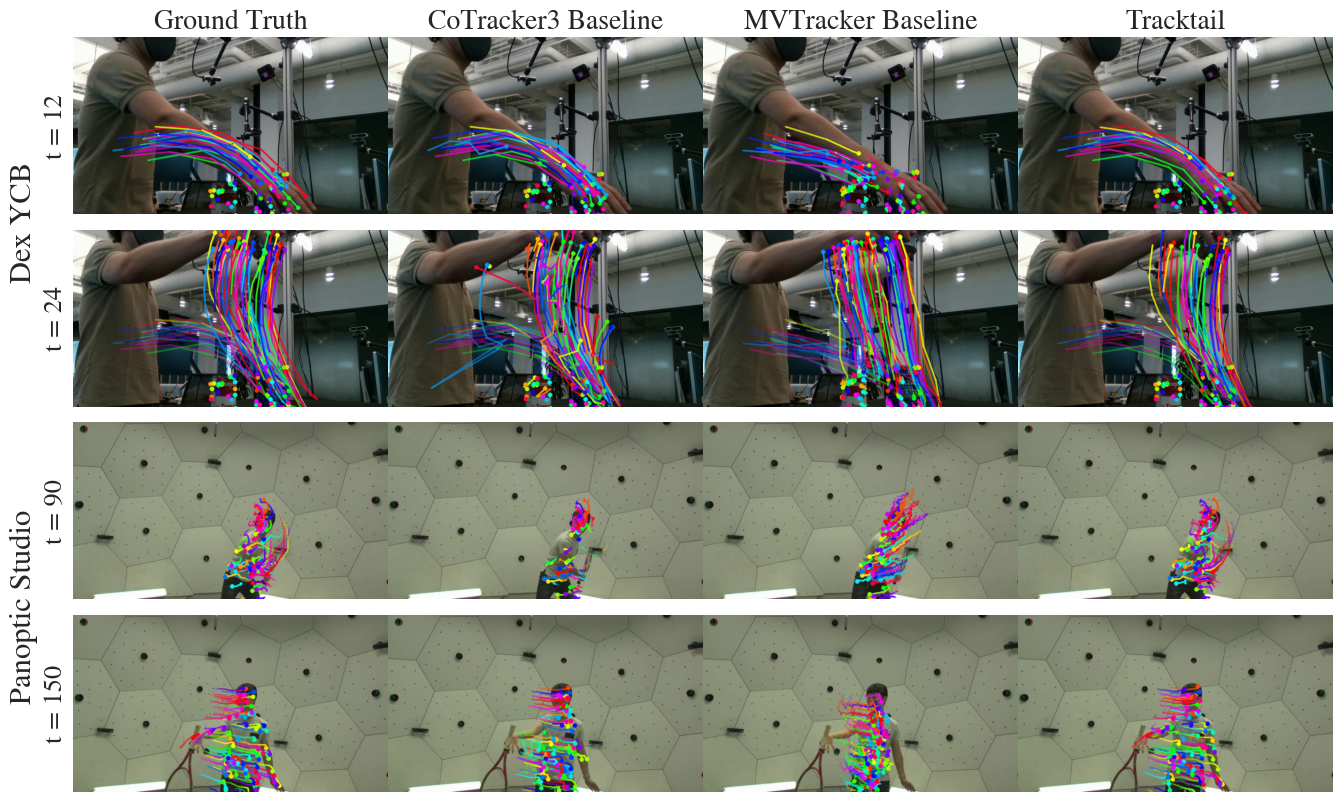

In [63]:
fs = 20
sns.set_style('ticks', {'font.family': 'STIXGeneral'})

fig = plt.figure(figsize=(14, 10))

# 4 rows × 4 methods
gs = gridspec.GridSpec(
    4, 4,
    wspace=0.0,
    hspace=0.0,
    left=0.05,
    right=0.95
)

axes = []

for row in range(4):
    axes.append([
        fig.add_subplot(gs[row, col])
        for col in range(4)
    ])

for row_idx, row_axes in enumerate(axes):
    for col_idx, ax in enumerate(row_axes):

        method = methods[col_idx]
        view = specs[row_idx // 2]['views'][0]
        view_num = ''.join(c for c in view if c.isdigit())
        frame_num = specs[row_idx // 2]['frames'][row_idx % 2]
        dataset = specs[row_idx // 2]['dataset']

        video_path = os.path.join(video_prefixes[dataset][method], f'{view}.mp4')
        cap = cv2.VideoCapture(video_path)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_num)
        ret, img = cap.read()
        cap.release()
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # center-crop to 16:9 so all rows share the same aspect ratio
        target_ar = 16 / 9
        h, w = img.shape[:2]
        if w / h < target_ar:          # too tall (e.g. 4:3 dex-ycb) -> trim top/bottom
            new_h = int(round(w / target_ar))
            y0 = (h - new_h) // 2
            img = img[y0:y0 + new_h]
        elif w / h > target_ar:        # too wide -> trim left/right
            new_w = int(round(h * target_ar))
            x0 = (w - new_w) // 2
            img = img[:, x0:x0 + new_w]


        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        if row_idx == 0: 
            ax.set_title(f"{method}", fontsize=fs)
        if col_idx == 0:
            ax.set_ylabel(f"t = {frame_num + 1}", fontsize = fs - 1)

for row in axes:
    for ax in row:
        for spine in ax.spines.values():
            spine.set_visible(False)

# fig.canvas.draw()
# for i, method in enumerate(methods):
#     ax = axes[0][i]

#     x_center = (
#         ax.get_position().x0 +
#         ax.get_position().x1
#     ) / 2

#     fig.text(x_center, 0.92, method, ha='center', fontsize=fs + 2, transform=fig.transFigure)
    

dataset_names = ['Dex YCB', 'Panoptic Studio']
for dataset_idx, dataset_name in enumerate(dataset_names):

    row_top = dataset_idx * 2
    row_bottom = row_top + 1

    top_pos = axes[row_top][0].get_position()
    bottom_pos = axes[row_bottom][0].get_position()

    y_center = (
        top_pos.y0 + bottom_pos.y1
    ) / 2

    fig.text(
        0.015,
        y_center,
        dataset_name,
        ha='center',
        va='center',
        rotation=90,
        fontsize=fs + 2,
        transform=fig.transFigure
    )

outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)

fig.savefig(os.path.join(outpath, 'qualitative_comparison.pdf'), dpi=800, bbox_inches='tight')


In [ ]:
# fs = 20
# sns.set_style('ticks', {'font.family': 'STIXGeneral'})

# fig = plt.figure(figsize=(20, 4.5))
# gs = gridspec.GridSpec(1, 4, wspace=0.01, left=0.05, right=0.95)
# gs_gt    = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[0], wspace=0, hspace=0.01)
# gs_left  = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[1], wspace=0, hspace=0.01)
# gs_mid   = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[2], wspace=0, hspace=0.01)
# gs_right = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[3], wspace=0, hspace=0.01)

# axes = []
# for row in range(2):
#     axes.append([
#         fig.add_subplot(gs_gt[row, 0]),
#         fig.add_subplot(gs_gt[row, 1]),
#         fig.add_subplot(gs_left[row, 0]),
#         fig.add_subplot(gs_left[row, 1]),
#         fig.add_subplot(gs_mid[row, 0]),
#         fig.add_subplot(gs_mid[row, 1]),
#         fig.add_subplot(gs_right[row, 0]),
#         fig.add_subplot(gs_right[row, 1]),
#     ])

# for row_idx, row_axes in enumerate(axes):
#     for col_idx, ax in enumerate(row_axes):

#         i = col_idx % 2
#         method = methods[col_idx // 2]
#         view = specs[row_idx // 2]['views'][i]
#         view_num = ''.join(c for c in view if c.isdigit())
#         frame_num = specs[row_idx // 2]['frames'][row_idx]

#         video_path = os.path.join(video_prefixes[row_idx // 2][method], f'{view}.mp4')
#         cap = cv2.VideoCapture(video_path)
#         cap.set(cv2.CAP_PROP_POS_FRAMES, frame_num)
#         ret, img = cap.read()
#         cap.release()
#         print(video_path)
#         img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

#         ax.imshow(img)
#         ax.set_xticks([])
#         ax.set_yticks([])
#         if row_idx == 0: 
#             ax.set_title(f"View {view_num}", fontsize=fs)
#         if col_idx == 0:
#             ax.set_ylabel(f"t = {frame_num + 1}", fontsize=fs)

# for row in axes:
#     for ax in row:
#         for spine in ax.spines.values():
#             spine.set_visible(False)

# fig.canvas.draw()
# for i, method in enumerate(methods):
#     ax_l = axes[0][i * 2]
#     ax_r = axes[0][i * 2 + 1]
#     x_center = (ax_l.get_position().x0 + ax_r.get_position().x1) / 2
#     fig.text(x_center, 0.96, method, ha='center', fontsize=fs + 2, transform=fig.transFigure)
    
# outdir = os.path.dirname(outpath)
# if outdir:
#     os.makedirs(outdir, exist_ok=True)

# fig.savefig(os.path.join(outpath, 'qualitative_comparison_supp.pdf'), dpi=800, bbox_inches='tight')
